<a href="https://colab.research.google.com/github/pendulumswings/pendulumswings.github.io/blob/main/scripts/chapter5/magic_kick.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

The Magic Kick: Shifting $\beta_c$ by Adding Initial Velocity.

Calculated Magic Kick Kappa: 0.0303


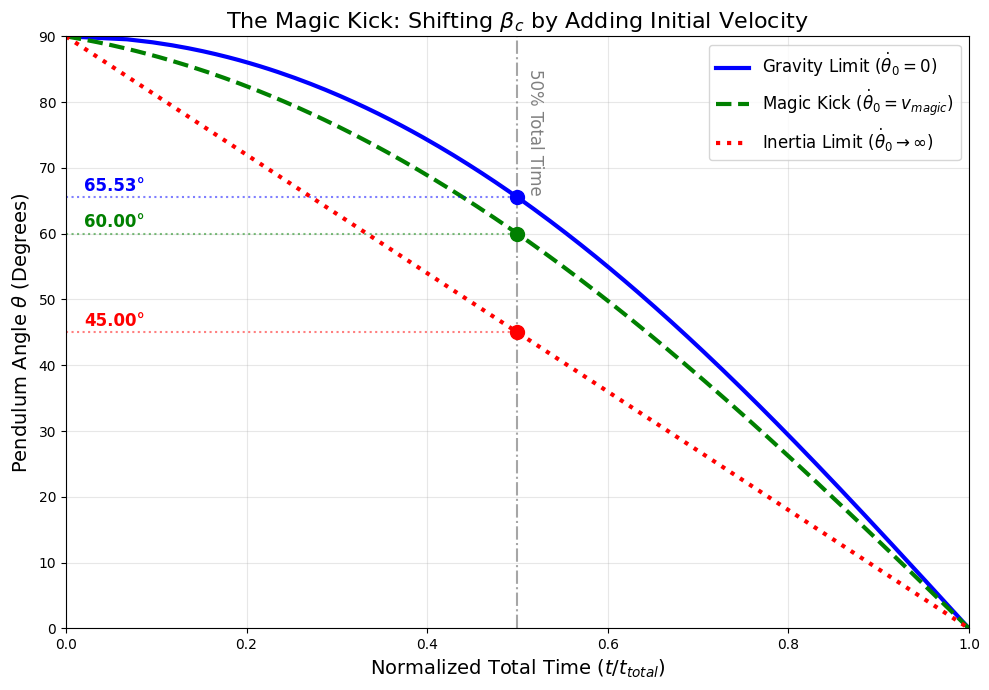

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.optimize import root_scalar

# 1. Root finder to dynamically calculate the exact "Magic Kick" kappa
def time_diff(kappa, theta0_rad=np.pi/2, thetac_rad=np.pi/3):
    # Time to fall from theta0 to thetac
    t_top = quad(lambda x: 1/np.sqrt(kappa + np.cos(x)), thetac_rad, theta0_rad)[0]
    # Time to fall from thetac to 0
    t_bottom = quad(lambda x: 1/np.sqrt(kappa + np.cos(x)), 0, thetac_rad)[0]
    return t_top - t_bottom

# Solve for the exact kappa that makes t_top == t_bottom
res = root_scalar(time_diff, bracket=[0.01, 10.0], method='brentq')
kappa_magic = res.root
print(f"Calculated Magic Kick Kappa: {kappa_magic:.4f}")

# 2. Setup the angles for integration (90 degrees down to 0 degrees)
angles_deg = np.linspace(90, 0, 200)
angles_rad = np.radians(angles_deg)

def calc_normalized_time(kappa):
    times = []
    for ang in angles_rad:
        # Integrate from current angle up to 90 degrees to get time spent
        t = quad(lambda x: 1/np.sqrt(kappa + np.cos(x)), ang, np.pi/2)[0]
        times.append(t)
    times = np.array(times)
    return times / times[-1] # Normalize so total time is exactly 1.0

# Calculate trajectories
t_gravity = calc_normalized_time(0.0)           # Dropped from rest
t_magic = calc_normalized_time(kappa_magic)     # The Magic Kick
t_inertia = calc_normalized_time(1e6)           # Cannonball / Infinite velocity

# 3. Plotting
plt.figure(figsize=(10, 7))

# Plot the three regimes
plt.plot(t_gravity, angles_deg, color='blue', lw=3, label=r'Gravity Limit ($\dot{\theta}_0 = 0$)')
plt.plot(t_magic, angles_deg, color='green', lw=3, linestyle='--', label=rf'Magic Kick ($\dot{{\theta}}_0 = v_{{magic}}$)')
plt.plot(t_inertia, angles_deg, color='red', lw=3, linestyle=':', label=r'Inertia Limit ($\dot{\theta}_0 \to \infty$)')

# Add the 50% Time marker
plt.axvline(x=0.5, color='gray', linestyle='-.', alpha=0.7)
plt.text(0.51, 85, '50% Total Time', rotation=-90, color='gray', fontsize=12, va='top')

# Highlight the crossing points (beta_c values)
crossings = [(0.5, 65.53, 'blue'), (0.5, 60.0, 'green'), (0.5, 45.0, 'red')]
for x, y, color in crossings:
    plt.scatter([x], [y], color=color, s=100, zorder=5)
    plt.hlines(y, xmin=0, xmax=x, colors=color, linestyles='dotted', alpha=0.5)
    plt.text(0.02, y+1, f'{y:.2f}°', color=color, fontsize=12, fontweight='bold')

plt.title(r'The Magic Kick: Shifting $\beta_c$ by Adding Initial Velocity', fontsize=16)
plt.xlabel('Normalized Total Time ($t / t_{total}$)', fontsize=14)
plt.ylabel(r'Pendulum Angle $\theta$ (Degrees)', fontsize=14)
plt.xlim(0, 1)
plt.ylim(0, 90)
plt.grid(True, alpha=0.3)
plt.legend(loc='upper right', fontsize=12)

plt.tight_layout()
plt.show()